# PD — EDA

Explore distributions, target balance, missingness and initial relationships.


In [1]:
# ==========================================
# PD — Exploratory Data Analysis
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ruta del dataset
DATA_PATH = "../data/raw/cs-training.csv"

# Cargar dataset
df = pd.read_csv(DATA_PATH)

print("Dataset cargado correctamente.")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")


Dataset cargado correctamente.
Filas: 150,000
Columnas: 12


In [2]:
# ==========================================
# Estructura del dataset
# ==========================================

print("Nombres de las variables:")
print(df.columns.tolist())

print("\nTipos de datos:")
display(df.dtypes)

Nombres de las variables:
['Unnamed: 0', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Tipos de datos:


Unnamed: 0                                int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

In [3]:
# ==========================================
# Primeras observaciones
# ==========================================

display(df.head(10))

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,6,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
7,8,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,9,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
9,10,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [4]:
# ==========================================
# Análisis de valores faltantes
# ==========================================

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100
})

missing = missing.sort_values("missing_count", ascending=False)

display(missing)

,missing_count,missing_pct
MonthlyIncome,29731,19.820667
NumberOfDependents,3924,2.616000
Unnamed: 0,0,0.000000
SeriousDlqin2yrs,0,0.000000
age,0,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
DebtRatio,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000


In [5]:
# ==========================================
# Distribución de la variable objetivo
# ==========================================

target_counts = df["SeriousDlqin2yrs"].value_counts().sort_index()

target_pct = (
    df["SeriousDlqin2yrs"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_pct
})

display(target_summary)

,count,percentage
SeriousDlqin2yrs,,
0,139974,93.316
1,10026,6.684


In [6]:
# ==========================================
# Estadísticas descriptivas
# ==========================================

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,150000.0,75000.500000,43301.414527,1.0,37500.750000,75000.500000,112500.250000,150000.0
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0


In [7]:
# ==========================================
# Identificación de valores sospechosos
# ==========================================

checks = {
    "age_0": (df["age"] == 0).sum(),
    "age_over_100": (df["age"] > 100).sum(),
    "utilization_over_1": (
        df["RevolvingUtilizationOfUnsecuredLines"] > 1
    ).sum(),
    "debt_ratio_over_1": (
        df["DebtRatio"] > 1
    ).sum(),
    "late_30_59_98": (
        df["NumberOfTime30-59DaysPastDueNotWorse"] == 98
    ).sum(),
    "late_90_98": (
        df["NumberOfTimes90DaysLate"] == 98
    ).sum(),
    "late_60_89_98": (
        df["NumberOfTime60-89DaysPastDueNotWorse"] == 98
    ).sum(),
}

suspicious = pd.DataFrame(
    checks.items(),
    columns=["condition", "count"]
)

suspicious["percentage"] = (
    suspicious["count"] / len(df) * 100
)

display(suspicious)

,condition,count,percentage
0,age_0,1,0.000667
1,age_over_100,13,0.008667
2,utilization_over_1,3321,2.214000
3,debt_ratio_over_1,35137,23.424667
4,late_30_59_98,264,0.176000
5,late_90_98,264,0.176000
6,late_60_89_98,264,0.176000


In [8]:
# ==========================================
# Investigación de valores 98 en variables de mora
# ==========================================

late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse"
]

for col in late_cols:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index().tail(10))


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
6     140
7      54
8      25
9      12
10      4
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
9      19
10      8
11      5
12      2
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
3     318
4     105
5      34
6      16
7       9
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64


In [9]:
# ==========================================
# Default rate para valores 98
# ==========================================

for col in late_cols:
    summary_98 = (
        df.groupby(df[col] == 98)["SeriousDlqin2yrs"]
        .agg(["count", "mean"])
        .rename(index={False: "Valor distinto de 98", True: "Valor = 98"})
    )

    summary_98["default_rate_pct"] = summary_98["mean"] * 100

    print(f"\n{col}")
    display(summary_98)


NumberOfTime30-59DaysPastDueNotWorse


,count,mean,default_rate_pct
NumberOfTime30-59DaysPastDueNotWorse,,,
Valor distinto de 98,149736,0.066003,6.600283
Valor = 98,264,0.541667,54.166667



NumberOfTimes90DaysLate


,count,mean,default_rate_pct
NumberOfTimes90DaysLate,,,
Valor distinto de 98,149736,0.066003,6.600283
Valor = 98,264,0.541667,54.166667



NumberOfTime60-89DaysPastDueNotWorse


,count,mean,default_rate_pct
NumberOfTime60-89DaysPastDueNotWorse,,,
Valor distinto de 98,149736,0.066003,6.600283
Valor = 98,264,0.541667,54.166667


In [10]:
# ==========================================
# Coincidencia de los valores 98
# ==========================================

mask_98 = (
    (df["NumberOfTime30-59DaysPastDueNotWorse"] == 98) &
    (df["NumberOfTimes90DaysLate"] == 98) &
    (df["NumberOfTime60-89DaysPastDueNotWorse"] == 98)
)

print(f"Registros con 98 en las tres variables: {mask_98.sum():,}")

print("\nCombinaciones de valores en las tres variables:")
display(
    df.loc[mask_98, late_cols]
    .value_counts()
    .reset_index(name="count")
)

Registros con 98 en las tres variables: 264

Combinaciones de valores en las tres variables:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,count
0,98,98,98,264


In [11]:
# ==========================================
# Investigación de valores 96
# ==========================================

for col in late_cols:
    mask_96 = df[col] == 96
    
    print(f"\n{col}")
    print(f"Registros con valor 96: {mask_96.sum():,}")
    
    if mask_96.sum() > 0:
        default_rate = df.loc[mask_96, "SeriousDlqin2yrs"].mean() * 100
        print(f"Default rate: {default_rate:.2f}%")


NumberOfTime30-59DaysPastDueNotWorse
Registros con valor 96: 5
Default rate: 80.00%

NumberOfTimes90DaysLate
Registros con valor 96: 5
Default rate: 80.00%

NumberOfTime60-89DaysPastDueNotWorse
Registros con valor 96: 5
Default rate: 80.00%


In [12]:
# ==========================================
# Coincidencia de los valores 96
# ==========================================

mask_96_all = (
    (df["NumberOfTime30-59DaysPastDueNotWorse"] == 96) &
    (df["NumberOfTimes90DaysLate"] == 96) &
    (df["NumberOfTime60-89DaysPastDueNotWorse"] == 96)
)

print(f"Registros con 96 en las tres variables: {mask_96_all.sum():,}")

display(
    df.loc[mask_96_all, late_cols]
)

Registros con 96 en las tres variables: 5


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse
41944,96,96,96
69478,96,96,96
84167,96,96,96
94106,96,96,96
120049,96,96,96


In [13]:
# ==========================================
# Investigación de edad = 0
# ==========================================

age_zero = df["age"] == 0

print(f"Registros con age = 0: {age_zero.sum():,}")

if age_zero.sum() > 0:
    print(
        f"Default rate en age = 0: "
        f"{df.loc[age_zero, 'SeriousDlqin2yrs'].mean() * 100:.2f}%"
    )

    display(
        df.loc[age_zero]
    )

Registros con age = 0: 1
Default rate en age = 0: 0.00%


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65695,65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


In [14]:
# ==========================================
# Investigación de DebtRatio > 1
# ==========================================

debt_ratio_high = df["DebtRatio"] > 1

debt_ratio_summary = pd.DataFrame({
    "count": [
        debt_ratio_high.sum(),
        (~debt_ratio_high).sum()
    ],
    "default_rate_pct": [
        df.loc[debt_ratio_high, "SeriousDlqin2yrs"].mean() * 100,
        df.loc[~debt_ratio_high, "SeriousDlqin2yrs"].mean() * 100
    ],
    "monthly_income_missing_pct": [
        df.loc[debt_ratio_high, "MonthlyIncome"].isna().mean() * 100,
        df.loc[~debt_ratio_high, "MonthlyIncome"].isna().mean() * 100
    ]
}, index=["DebtRatio > 1", "DebtRatio <= 1"])

display(debt_ratio_summary)

,count,default_rate_pct,monthly_income_missing_pct
DebtRatio > 1,35137,6.520192,79.414862
DebtRatio <= 1,114863,6.734109,1.590591


In [15]:
# ==========================================
# Investigación de utilización de crédito > 1
# ==========================================

util_high = df["RevolvingUtilizationOfUnsecuredLines"] > 1

util_summary = pd.DataFrame({
    "count": [
        util_high.sum(),
        (~util_high).sum()
    ],
    "default_rate_pct": [
        df.loc[util_high, "SeriousDlqin2yrs"].mean() * 100,
        df.loc[~util_high, "SeriousDlqin2yrs"].mean() * 100
    ],
    "monthly_income_missing_pct": [
        df.loc[util_high, "MonthlyIncome"].isna().mean() * 100,
        df.loc[~util_high, "MonthlyIncome"].isna().mean() * 100
    ]
}, index=["Utilization > 1", "Utilization <= 1"])

display(util_summary)

,count,default_rate_pct,monthly_income_missing_pct
Utilization > 1,3321,37.247817,16.501054
Utilization <= 1,146679,5.991996,19.895827


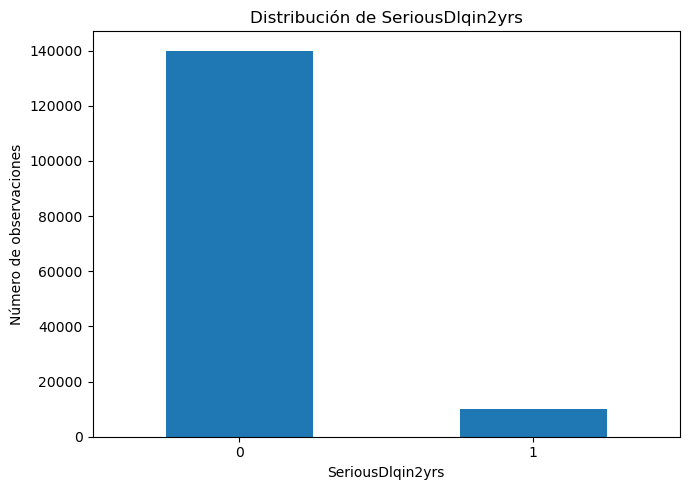

In [16]:
# ==========================================
# Distribución del target
# ==========================================

plt.figure(figsize=(7, 5))

target_counts.plot(
    kind="bar"
)

plt.title("Distribución de SeriousDlqin2yrs")
plt.xlabel("SeriousDlqin2yrs")
plt.ylabel("Número de observaciones")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# Default rate por grupo de edad
# ==========================================

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 75, 120],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66-75",
        "76+"
    ],
    include_lowest=True
)

age_default_rate = (
    df.groupby("age_group", observed=False)["SeriousDlqin2yrs"]
    .mean()
    .mul(100)
    .reset_index(name="default_rate_pct")
)

display(age_default_rate)

,age_group,default_rate_pct
0,18-25,11.162483
1,26-35,11.122548
2,36-45,8.813173
3,46-55,7.593350
4,56-65,4.583009
5,66-75,2.615051
6,76+,2.043637


In [18]:
df.drop(columns=["age_group"], inplace=True)

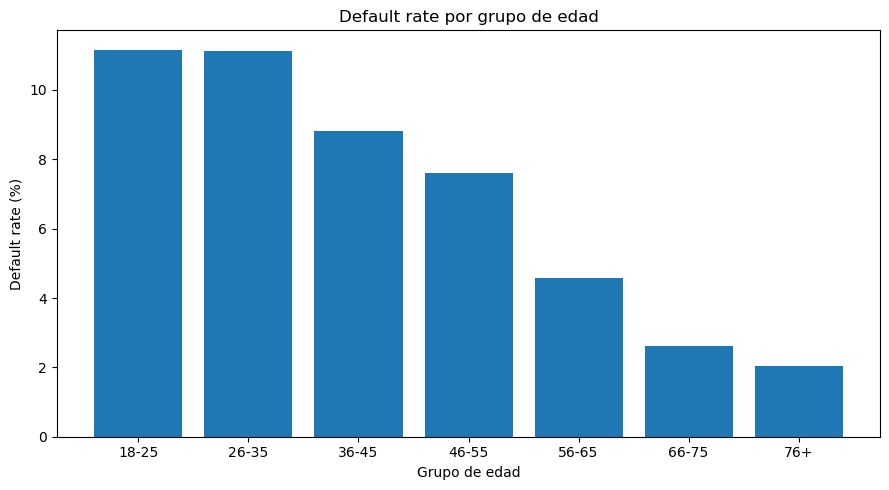

In [19]:
# ==========================================
# Default rate por grupo de edad
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    age_default_rate["age_group"].astype(str),
    age_default_rate["default_rate_pct"]
)

plt.title("Default rate por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Default rate (%)")

plt.tight_layout()
plt.show()

In [20]:
# ==========================================
# Default rate por nivel de utilización
# ==========================================

df["utilization_group"] = pd.cut(
    df["RevolvingUtilizationOfUnsecuredLines"],
    bins=[-np.inf, 0.1, 0.3, 0.5, 0.8, 1, 2, 10, np.inf],
    labels=[
        "<= 0.1",
        "0.1-0.3",
        "0.3-0.5",
        "0.5-0.8",
        "0.8-1.0",
        "1-2",
        "2-10",
        "> 10"
    ]
)

utilization_default_rate = (
    df.groupby("utilization_group", observed=False)["SeriousDlqin2yrs"]
    .mean()
    .mul(100)
    .reset_index(name="default_rate_pct")
)

display(utilization_default_rate)

,utilization_group,default_rate_pct
0,<= 0.1,1.810447
1,0.1-0.3,3.142777
2,0.3-0.5,5.849653
3,0.5-0.8,10.776849
4,0.8-1.0,18.618192
5,1-2,40.101695
6,2-10,28.461538
7,> 10,7.053942


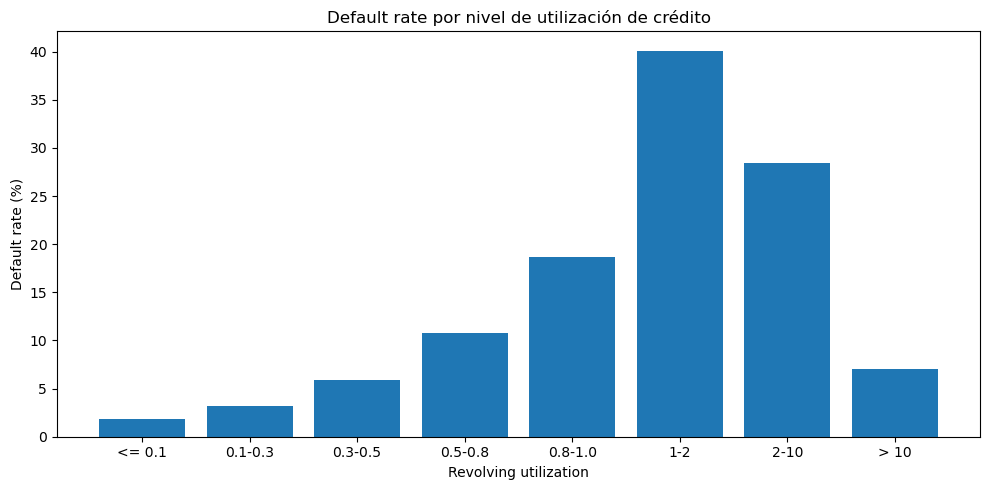

In [21]:
# ==========================================
# Default rate por nivel de utilización
# ==========================================

plt.figure(figsize=(10, 5))

plt.bar(
    utilization_default_rate["utilization_group"].astype(str),
    utilization_default_rate["default_rate_pct"]
)

plt.title("Default rate por nivel de utilización de crédito")
plt.xlabel("Revolving utilization")
plt.ylabel("Default rate (%)")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [22]:
# ==========================================
# Default rate por número de atrasos
# ==========================================

late_default_rates = {}

for col in late_cols:
    temp = (
        df.groupby(col)["SeriousDlqin2yrs"]
        .agg(["count", "mean"])
        .rename(columns={"mean": "default_rate"})
    )

    temp["default_rate"] = temp["default_rate"] * 100
    late_default_rates[col] = temp

    print(f"\n{'=' * 70}")
    print(col)
    print(f"{'=' * 70}")

    display(temp.tail(15))


NumberOfTime30-59DaysPastDueNotWorse


,count,default_rate
NumberOfTime30-59DaysPastDueNotWorse,,
1,16033,15.025260
2,4598,26.511527
3,1754,35.233751
4,747,42.570281
5,342,45.029240
6,140,52.857143
7,54,51.851852
8,25,32.000000
9,12,33.333333



NumberOfTimes90DaysLate


,count,default_rate
NumberOfTimes90DaysLate,,
4,291,67.010309
5,131,63.358779
6,80,60.000000
7,38,81.578947
8,21,71.428571
9,19,73.684211
10,8,62.500000
11,5,60.000000
12,2,50.000000



NumberOfTime60-89DaysPastDueNotWorse


,count,default_rate
NumberOfTime60-89DaysPastDueNotWorse,,
0,142396,5.095649
1,5731,31.006805
2,1118,50.178891
3,318,56.603774
4,105,61.904762
5,34,61.764706
6,16,75.000000
7,9,55.555556
8,2,50.000000


In [23]:
# ==========================================
# Default rate de las variables de mora
# ==========================================

late_plot_data = []

for col in late_cols:
    temp = (
        df.groupby(col)["SeriousDlqin2yrs"]
        .agg(["count", "mean"])
        .reset_index()
    )

    temp["default_rate_pct"] = temp["mean"] * 100
    temp["variable"] = col

    late_plot_data.append(temp)

late_plot_data = pd.concat(late_plot_data, ignore_index=True)

# Mostrar solamente valores de mora entre 0 y 7
# para evitar que los valores especiales 96 y 98 dominen la visualización.

late_plot_filtered = late_plot_data[
    late_plot_data.iloc[:, 0].between(0, 7)
]

display(
    late_plot_filtered[
        [late_plot_filtered.columns[0], "count",
         "default_rate_pct", "variable"]
    ]
)

,NumberOfTime30-59DaysPastDueNotWorse,count,default_rate_pct,variable
0,0.0,126018,4.000222,NumberOfTime30-59DaysPastDueNotWorse
1,1.0,16033,15.025260,NumberOfTime30-59DaysPastDueNotWorse
2,2.0,4598,26.511527,NumberOfTime30-59DaysPastDueNotWorse
3,3.0,1754,35.233751,NumberOfTime30-59DaysPastDueNotWorse
4,4.0,747,42.570281,NumberOfTime30-59DaysPastDueNotWorse
5,5.0,342,45.029240,NumberOfTime30-59DaysPastDueNotWorse
6,6.0,140,52.857143,NumberOfTime30-59DaysPastDueNotWorse
7,7.0,54,51.851852,NumberOfTime30-59DaysPastDueNotWorse


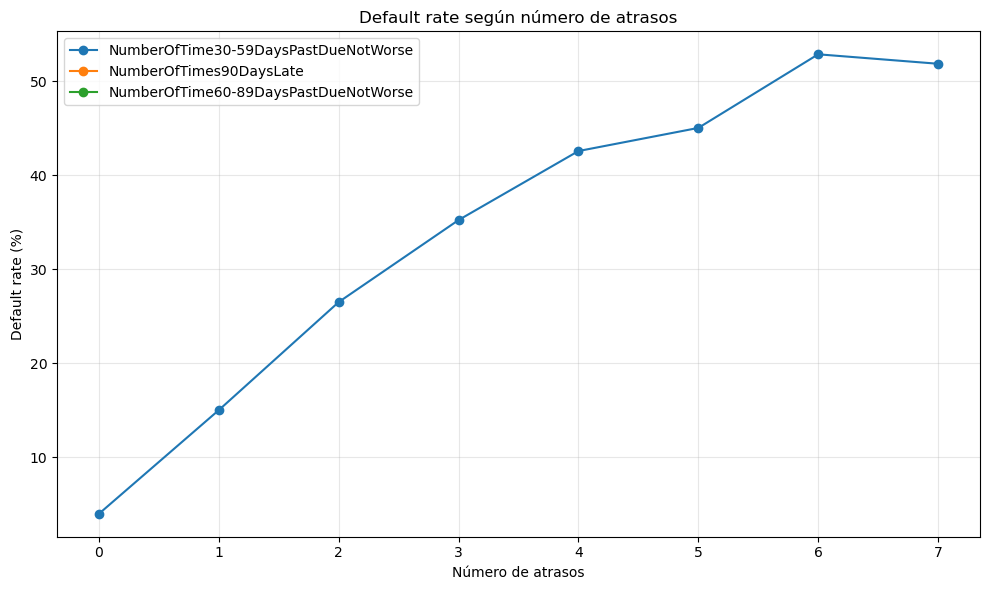

In [24]:
# ==========================================
# Gráfico: default rate según número de atrasos
# ==========================================

plt.figure(figsize=(10, 6))

for col in late_cols:
    temp = late_plot_data[
        (late_plot_data["variable"] == col) &
        (late_plot_data.iloc[:, 0].between(0, 7))
    ]

    x = temp.iloc[:, 0]
    y = temp["default_rate_pct"]

    plt.plot(
        x,
        y,
        marker="o",
        label=col
    )

plt.title("Default rate según número de atrasos")
plt.xlabel("Número de atrasos")
plt.ylabel("Default rate (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

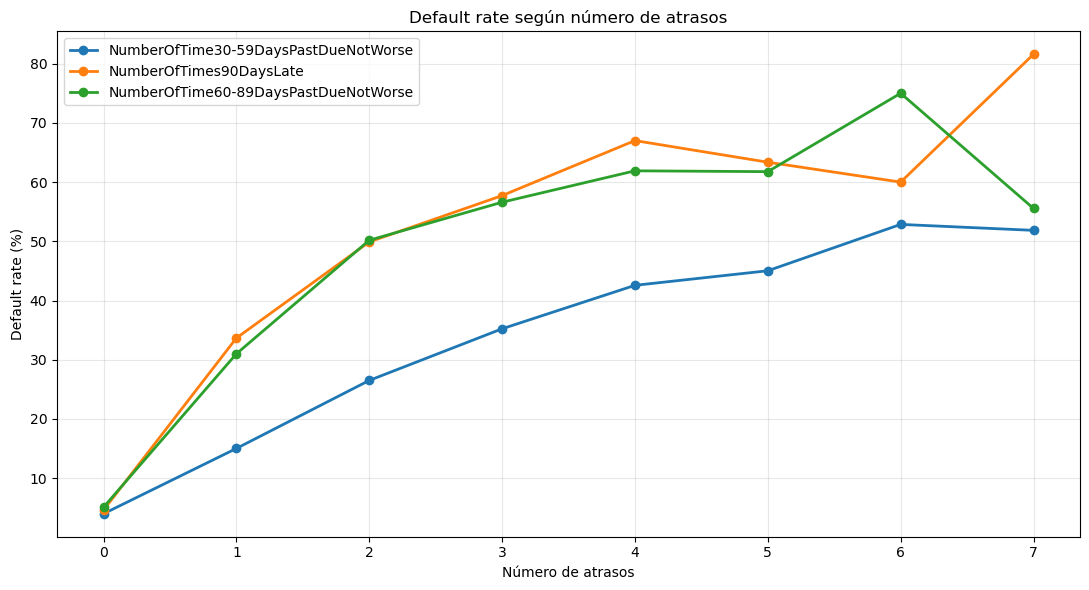

In [25]:
# ==========================================
# Gráfico de default rate por atrasos
# ==========================================

plt.figure(figsize=(11, 6))

for col in late_cols:

    temp = (
        df.groupby(col)["SeriousDlqin2yrs"]
        .agg(["count", "mean"])
        .reset_index()
    )

    # Convertir default rate a porcentaje
    temp["default_rate_pct"] = temp["mean"] * 100

    # Mantener solamente valores de 0 a 7
    temp = temp[temp[col].between(0, 7)]

    plt.plot(
        temp[col],
        temp["default_rate_pct"],
        marker="o",
        linewidth=2,
        label=col
    )

plt.title("Default rate según número de atrasos")
plt.xlabel("Número de atrasos")
plt.ylabel("Default rate (%)")

plt.xticks(range(0, 8))
plt.legend()

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# Comparación de variables por target
# ==========================================

features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

comparison = (
    df.groupby("SeriousDlqin2yrs")[features]
    .median()
    .T
    .rename(columns={
        0: "Mediana_Default_0",
        1: "Mediana_Default_1"
    })
)

comparison["Diferencia"] = (
    comparison["Mediana_Default_1"]
    - comparison["Mediana_Default_0"]
)

display(comparison)

SeriousDlqin2yrs,Mediana_Default_0,Mediana_Default_1,Diferencia
RevolvingUtilizationOfUnsecuredLines,0.133288,0.838853,0.705565
age,52.000000,45.000000,-7.000000
NumberOfTime30-59DaysPastDueNotWorse,0.000000,0.000000,0.000000
DebtRatio,0.362659,0.428227,0.065568
MonthlyIncome,5466.000000,4500.000000,-966.000000
NumberOfOpenCreditLinesAndLoans,8.000000,7.000000,-1.000000
NumberOfTimes90DaysLate,0.000000,0.000000,0.000000
NumberRealEstateLoansOrLines,1.000000,1.000000,0.000000
NumberOfTime60-89DaysPastDueNotWorse,0.000000,0.000000,0.000000
NumberOfDependents,0.000000,0.000000,0.000000


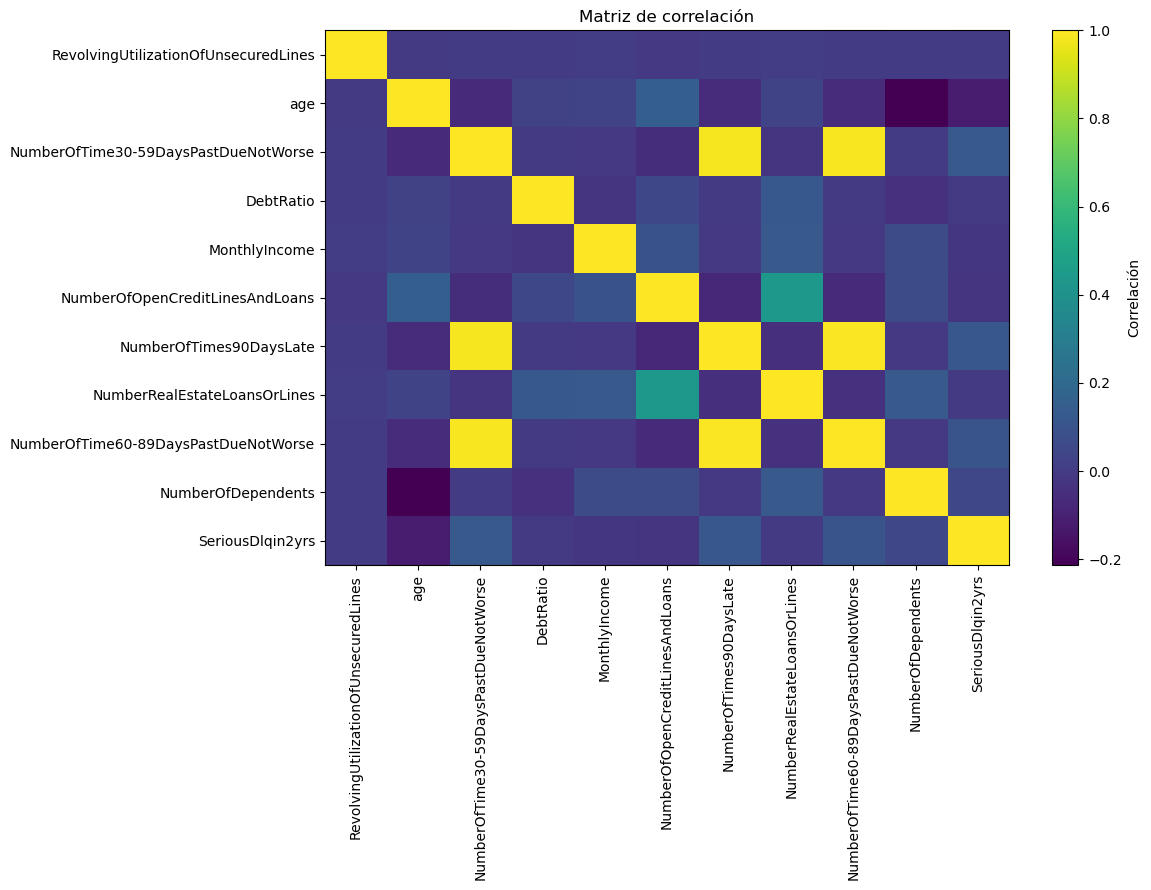

In [27]:
# ==========================================
# Matriz de correlación
# ==========================================

corr_features = features + ["SeriousDlqin2yrs"]

corr_matrix = df[corr_features].corr()

plt.figure(figsize=(12, 9))

plt.imshow(
    corr_matrix,
    aspect="auto"
)

plt.colorbar(label="Correlación")

plt.xticks(
    range(len(corr_features)),
    corr_features,
    rotation=90
)

plt.yticks(
    range(len(corr_features)),
    corr_features
)

plt.title("Matriz de correlación")

plt.tight_layout()
plt.show()

In [28]:
# ==========================================
# Correlación de variables con el target
# ==========================================

target_corr = (
    corr_matrix["SeriousDlqin2yrs"]
    .drop("SeriousDlqin2yrs")
    .sort_values(key=abs, ascending=False)
)

target_corr_df = target_corr.to_frame(name="correlation_with_target")

display(target_corr_df)

,correlation_with_target
NumberOfTime30-59DaysPastDueNotWorse,0.125587
NumberOfTimes90DaysLate,0.117175
age,-0.115386
NumberOfTime60-89DaysPastDueNotWorse,0.102261
NumberOfDependents,0.046048
NumberOfOpenCreditLinesAndLoans,-0.029669
MonthlyIncome,-0.019746
DebtRatio,-0.007602
NumberRealEstateLoansOrLines,-0.007038
RevolvingUtilizationOfUnsecuredLines,-0.001802


# Conclusiones del EDA

## Principales hallazgos

1. El dataset contiene 150,000 observaciones y 12 variables.

2. La variable objetivo `SeriousDlqin2yrs` presenta un desbalance importante:
   - 93.316% de observaciones con target = 0.
   - 6.684% de observaciones con target = 1.

3. `MonthlyIncome` presenta aproximadamente 19.82% de valores faltantes y
   `NumberOfDependents` aproximadamente 2.62%.

4. Se identificaron valores especiales `96` y `98` en las variables de
   historial de mora:
   - `NumberOfTime30-59DaysPastDueNotWorse`
   - `NumberOfTimes90DaysLate`
   - `NumberOfTime60-89DaysPastDueNotWorse`

5. Estos valores especiales presentan tasas de default diferentes al resto
   de las observaciones y serán investigados formalmente en la etapa de
   Data Quality.

6. Se observó una relación decreciente entre edad y default rate por grupos
   de edad.

7. La utilización de crédito presenta una relación no lineal con el default.
   Los niveles cercanos y superiores a 1 muestran tasas de default elevadas,
   mientras que algunos valores extremos presentan comportamientos
   diferentes.

8. Las variables de historial de mora muestran una asociación positiva con
   el default rate. En general, una mayor frecuencia de atrasos se relaciona
   con mayores tasas observadas de default.

9. Las variables de mora presentan correlaciones entre sí, por lo que se
   deberá evaluar la posible multicolinealidad antes del modelamiento
   mediante Regresión Logística.

10. La correlación lineal con el target no es suficiente para evaluar la
    utilidad predictiva de una variable. El caso de
    `RevolvingUtilizationOfUnsecuredLines` muestra una relación no lineal
    que no queda reflejada adecuadamente mediante la correlación de Pearson.

## Próximo paso

El siguiente notebook será `02_data_quality.ipynb`, donde se realizará el
tratamiento formal de:

- valores faltantes;
- valores especiales 96 y 98;
- variable identificadora `Unnamed: 0`;
- valores extremos;
- consistencia de las variables;
- preparación del dataset para Feature Engineering y modelamiento PD.